## Parte 3: Aplicação de métodos — Classificação

**Dataset:** `dataset_grupo_22.csv`, com 2000 perfis de pacientes. **Variável a prever:** `target_class`, a categoria
diagnóstica (`DI_HY`, `HT`, `DI_HT`). O significado clínico dos códigos não é dado no enunciado.

### Objetivo
1. Aplicar **Regressão Logística** e **Análise Discriminante Linear (LDA)** e **decidir qual é o método mais
   adequado**, justificando.
2. Avaliar com os métodos de reamostragem: ***holdout***, **validação cruzada (k = 5 e k = 10)**, **LOOCV** e
   ***bootstrap***.
3. Escolher métricas adequadas e **explicar como a variância é afetada pelo método de reamostragem**.

### Ponto de partida: o que a EDA já nos disse
| Resultado da EDA | Consequência para a classificação |
|---|---|
| `target_class` é **muito desequilibrada**: 89.9% `DI_HY`, 5.85% `HT`, 4.25% `DI_HT` | Um modelo sem cuidados tende a prever quase sempre `DI_HY`. A *accuracy* engana; são precisas métricas por classe e **estratificação** na reamostragem. |
| `HbA1c_level` separa fortemente `HT` das outras classes (η² = 0.41); `triglycerides` separa `DI_HY` das minoritárias (η² = 0.105) | Esperamos que `HT` seja relativamente fácil de identificar e que estas sejam as features com mais peso. |
| `DI_HT` e `DI_HY` sobrepõem-se muito | `DI_HT` deve ser a classe mais difícil. |
| As distribuições são pouco "normais" (uniformes, assimétricas, caudas longas) | Os pressupostos da LDA podem não se verificar (verificamos em 2.1). |
| Artefacto de precisão decimal ligado à classe (EDA 3.8) | Logística e LDA usam o valor numérico de forma linear e não exploram as casas decimais; não criamos features a partir delas. |

## 1. Preparação dos dados

### 1.1 Carregamento dos dados e preparação do ambiente

Carregamos o dataset original (sem o alterar) e fixamos a semente aleatória em **22** (regra do projeto), para que
todas as divisões dos dados, validações cruzadas e reamostragens *bootstrap* sejam reprodutíveis.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, LeaveOneOut,
                                     cross_val_predict, cross_validate)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
dataset_path = next(p for p in [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name] if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dimensao do dataset:', raw.shape)
raw['target_class'].value_counts().to_frame('n').assign(**{'%': lambda d: d['n'] / len(raw) * 100})

Dimensao do dataset: (2000, 35)


,n,%
target_class,,
DI_HY,1798,89.900
HT,117,5.850
DI_HT,85,4.250


**Conclusões:** o dataset tem **2000 registos**: 1798 `DI_HY` (89.9%), 117 `HT` (5.85%) e **apenas 85 `DI_HT`
(4.25%)**. A classe maioritária é 21 vezes maior que a mais pequena. Este número vai condicionar tudo o que se segue:
a escolha das métricas, a necessidade de estratificar e o comportamento dos modelos.

### 1.2 Remoção de features, codificação e matriz de preditores

Aplicamos **a mesma preparação do notebook da regressão**, pelas mesmas razões (EDA, secção 4.2):
- removemos `calcium_baseline` (constante), `systolic_index` (cópia de `systolic_bp`) e `age_normalized` (reescala
  de `age`). As duas últimas tornariam a matriz de covariâncias **singular**, o que é um problema direto para a LDA,
  que tem de inverter essa matriz;
- convertemos as categóricas em números (ordinais → 0, 1, 2…; binárias → 0/1; `employment_status` → *one-hot*);
- **retiramos os dois targets dos preditores**: `target_class` é o que queremos prever e `target_regression` é o
  outro resultado do trabalho.

As restantes 31 features ficam todas. A seleção de features é o tema da Parte 4 (Ridge/Lasso); aqui o objetivo é
comparar métodos de classificação e de reamostragem nas mesmas condições.

In [2]:
TARGET = 'target_class'
CLASSES = ['DI_HY', 'HT', 'DI_HT']          # ordem fixa: maioritária -> minoritárias
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized']
ORDINAL = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_regression'])
y = data[TARGET]
assert X.isna().sum().sum() == 0
FEATURES = list(X.columns)
print(f'{X.shape[0]} registos x {len(FEATURES)} features')

2000 registos x 31 features


**Conclusões:** ficam **31 features** para os 2000 registos, sem valores em falta. Com cerca de 65 registos por
feature, há dados suficientes para estimar uma Regressão Logística ou uma LDA com covariância comum.

Ainda assim, a classe `DI_HT` tem só 85 pacientes. Isto inviabiliza, por exemplo, uma **QDA**: teria de estimar uma
matriz de covariâncias 31×31 (496 parâmetros) só com esses 85 pacientes, e a estimativa ficaria muito instável. É
uma das razões para nos ficarmos pelos dois métodos pedidos.

### 1.3 Métricas de avaliação: porque não basta a *accuracy*

A EDA mostrou que `target_class` é **muito desequilibrada** (≈ 90% `DI_HY`). Nestas condições, a *accuracy* engana:
um modelo que responda sempre `DI_HY` acerta em ≈ 90% dos casos sem ter aprendido nada. Usamos por isso as métricas
dos slides T4 (11–18), adaptadas a 3 classes:

| Métrica | O que mede | Porque é útil aqui |
|---|---|---|
| **Recall por classe** | Dos pacientes de cada classe, quantos foram bem identificados | Mostra diretamente se as classes raras (`HT`, `DI_HT`) estão a ser detetadas |
| **Precision por classe** | Das previsões de cada classe, quantas estão certas | Mostra o custo de "inventar" diagnósticos |
| **F1 macro** (métrica principal) | Média simples do F1 das 3 classes | Cada classe pesa o mesmo, por isso falhar uma classe rara baixa muito a métrica |
| **Balanced accuracy** | Média simples dos recalls das 3 classes | Um modelo que prevê sempre a maioritária fica em 1/3 = 0.333 |
| *Accuracy* | Proporção de acertos | Só como referência secundária |
| **Matriz de confusão** | Que classes são confundidas com quais | Diagnóstico detalhado dos erros |

Para tornar isto concreto, avaliamos um **classificador de referência** (*baseline*) que prevê sempre a classe
maioritária.

In [3]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {'f1_macro': f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
            'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'accuracy': accuracy_score(y_true, y_pred),
            **{f'recall_{c}': r for c, r in zip(CLASSES, rec)}}

baseline_pred = np.full(len(y), 'DI_HY')
pd.Series(metrics(y, baseline_pred), name='baseline (sempre DI_HY)').to_frame().T

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
baseline (sempre DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


**Conclusões:** o classificador que responde sempre `DI_HY` tem **accuracy de 0.899**, o que parece um bom
resultado. Mas não identifica **nenhum** paciente `HT` nem `DI_HT` (recall = 0), e por isso tem:
- **F1 macro = 0.316**;
- **balanced accuracy = 0.333** (= 1/3).

**Justificação:** é a prova numérica de que a *accuracy* não serve como métrica principal neste problema. Daqui em
diante, a métrica principal é o **F1 macro**, complementado pela **balanced accuracy** e pelo **recall de cada
classe**. Qualquer modelo útil tem de ficar claramente acima de 0.316 e 0.333.

## 2. Regressão Logística vs LDA

**Regressão Logística** (slides T3, 8–23): modela diretamente a probabilidade de cada classe,
$P(Y=k \mid X) = \frac{e^{\beta_{k0} + \beta_k^T x}}{\sum_j e^{\beta_{j0} + \beta_j^T x}}$ (versão multinomial),
com os coeficientes estimados por **máxima verosimilhança**. **Não assume nada** sobre a distribuição das features.

**LDA** (slides T3, 28–31): modela a distribuição das features **dentro de cada classe** como normal multivariada,
com uma **matriz de covariâncias comum**, e usa o teorema de Bayes,
$P(Y=k \mid X) \propto \pi_k \, f_k(x)$, onde $\pi_k$ é a probabilidade a priori da classe. As fronteiras de
decisão são lineares.

**Estratégia:**
1. verificar se os pressupostos da LDA se verificam nos nossos dados (2.1);
2. ajustar os dois métodos sem ajustes e ver o efeito do desequilíbrio (2.2);
3. corrigir o desequilíbrio e comparar (2.3);
4. testar se as diferenças são estatisticamente significativas (2.4).

### 2.1 Os pressupostos da LDA verificam-se?

A LDA (slides T3, 29–31) assume que, **dentro de cada classe**, as features seguem uma distribuição **normal** e que
**todas as classes têm a mesma matriz de covariâncias**. A Regressão Logística não faz estas suposições. Saber se os
pressupostos se verificam ajuda a perceber qual dos métodos deve funcionar melhor.

Verificamos, para as features mais discriminativas da EDA:
- a **normalidade dentro de cada classe** (teste de Shapiro-Wilk e assimetria);
- a **igualdade das variâncias entre classes** (teste de Levene e rácio entre o maior e o menor desvio padrão).

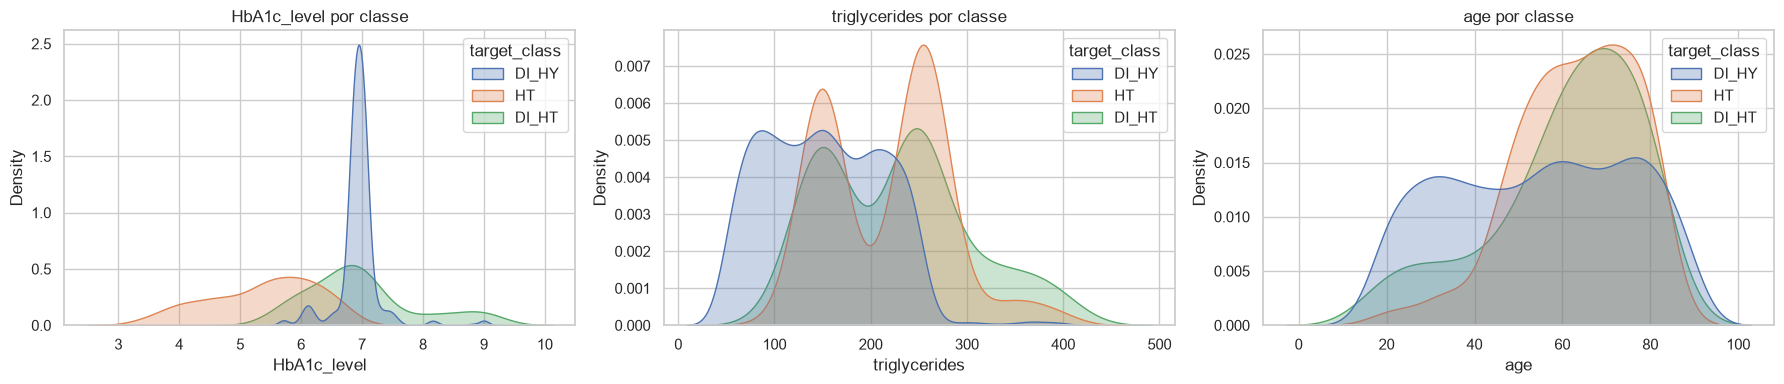

,std_DI_HY,std_HT,std_DI_HT,racio_std (max/min),p_Levene,skew_DI_HY,p_Shapiro_DI_HY
feature,,,,,,,
HbA1c_level,0.359,0.868,0.907,2.528,0.000,1.368,0.000
triglycerides,61.097,63.418,75.080,1.229,0.072,0.311,0.000
age,20.662,13.346,16.871,1.548,0.000,-0.080,0.000
bmi,7.285,6.013,5.819,1.252,0.000,0.086,0.000
blood_pressure,4.416,8.181,11.553,2.616,0.000,-0.733,0.000
crp_level,0.939,1.530,2.537,2.702,0.000,0.441,0.000


In [4]:
key = ['HbA1c_level', 'triglycerides', 'age', 'bmi', 'blood_pressure', 'crp_level']
rows = []
for f in key:
    groups = [data.loc[y == c, f] for c in CLASSES]
    stds = [g.std() for g in groups]
    rows.append({'feature': f,
                 **{f'std_{c}': s for c, s in zip(CLASSES, stds)},
                 'racio_std (max/min)': max(stds) / min(stds),
                 'p_Levene': stats.levene(*groups).pvalue,
                 'skew_DI_HY': stats.skew(groups[0]),
                 'p_Shapiro_DI_HY': stats.shapiro(groups[0].sample(500, random_state=SEED)).pvalue})
assumptions = pd.DataFrame(rows).set_index('feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, f in zip(axes, ['HbA1c_level', 'triglycerides', 'age']):
    sns.kdeplot(data=data, x=f, hue=y, hue_order=CLASSES, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(f'{f} por classe')
plt.tight_layout(); plt.show()
assumptions

**Conclusões:** **os pressupostos da LDA não se verificam.**
- **Normalidade:** o teste de Shapiro-Wilk rejeita a normalidade (p < 0.001) em todas as features testadas. Os
  gráficos mostram distribuições claramente não normais, por exemplo `HbA1c_level` muito concentrada em `DI_HY`
  (assimetria 1.37) e `age` aproximadamente uniforme.
- **Covariâncias iguais:** o teste de Levene rejeita variâncias iguais entre classes em 5 das 6 features. Em
  `HbA1c_level`, o desvio padrão das classes minoritárias (≈ 0.87–0.91) é **2.5 vezes** maior que o de `DI_HY`
  (0.36); em `blood_pressure` e `crp_level` o rácio também passa de 2.6.

**O que isto implica:** à partida, estas violações favorecem a Regressão Logística, que não depende destes
pressupostos. No entanto, a LDA é conhecida por ser **robusta** a violações moderadas: as suas fronteiras de decisão
continuam a ser lineares e podem funcionar bem, mesmo que as probabilidades estimadas não sejam exatas. Por isso, a
decisão entre os dois métodos tem de ser feita pelos **resultados**, e não apenas pela teoria.

Os gráficos confirmam também a EDA: `HbA1c_level` separa bem `HT` (valores mais baixos), `triglycerides` desloca
`HT` e `DI_HT` para valores mais altos, e as curvas de `DI_HT` e `DI_HY` sobrepõem-se muito.

### 2.2 Primeiro ajuste: Regressão Logística e LDA "tal como vêm"

Ajustamos os dois métodos com as opções por defeito do scikit-learn:
- **Regressão Logística multinomial** (generalização da logística para 3 classes, com *softmax*), estimada por máxima
  verosimilhança (slide T3, 13). As features são padronizadas (`StandardScaler`), porque o scikit-learn aplica por
  defeito uma pequena regularização que depende da escala;
- **LDA**, que estima as médias de cada classe, uma covariância comum e as **probabilidades a priori** πₖ a partir
  das proporções das classes no treino (slide T3, 30).

Para não depender de uma única divisão dos dados, usamos **validação cruzada estratificada 10-fold**: cada paciente
recebe uma previsão feita por um modelo que nunca o viu. É o método de reamostragem padrão; a secção 3 compara-o com
os outros.

**Hipótese a testar:** como ~90% dos pacientes são `DI_HY`, esperamos que os modelos sem ajuste prevejam
`DI_HY` na maioria dos casos e falhem as classes minoritárias.

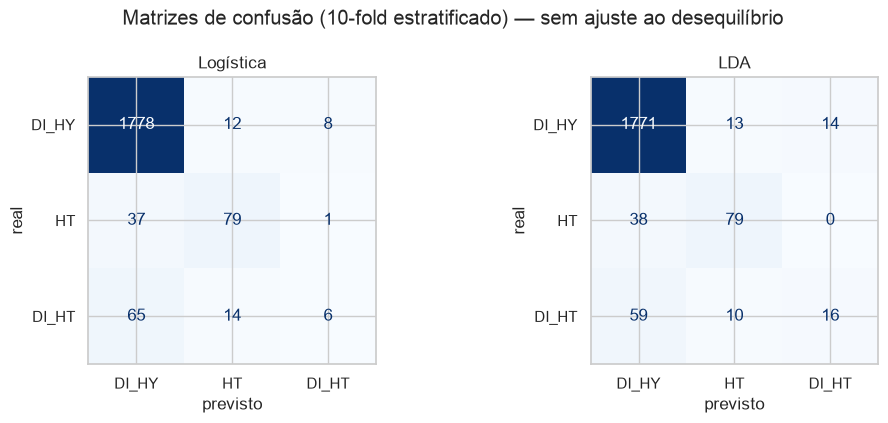

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logística,0.600,0.578,0.931,0.989,0.675,0.071
LDA,0.655,0.616,0.933,0.985,0.675,0.188
baseline (sempre DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


In [5]:
MODELS = {
    'Logística':          make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    'LDA':                make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    'Logística (pesos)':  make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight='balanced')),
    'LDA (priors iguais)': make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(priors=[1/3] * 3)),
}
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def show_confusions(names, preds, title):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.3))
    for ax, n in zip(np.atleast_1d(axes), names):
        ConfusionMatrixDisplay(confusion_matrix(y, preds[n], labels=CLASSES), display_labels=CLASSES).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(n); ax.set_xlabel('previsto'); ax.set_ylabel('real')
    fig.suptitle(title); plt.tight_layout(); plt.show()

cv_preds = {n: cross_val_predict(m, X, y, cv=CV10) for n, m in MODELS.items()}
show_confusions(['Logística', 'LDA'], cv_preds, 'Matrizes de confusão (10-fold estratificado) — sem ajuste ao desequilíbrio')
first = pd.DataFrame({n: metrics(y, cv_preds[n]) for n in ['Logística', 'LDA']}).T
first.loc['baseline (sempre DI_HY)'] = metrics(y, baseline_pred)
first

**Conclusões: a hipótese confirma-se.** Sem ajustes, os dois modelos preveem quase sempre `DI_HY`.

| | F1 macro | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|---|---|
| Baseline (sempre `DI_HY`) | 0.316 | 0.333 | 0.899 | 1.000 | 0.000 | 0.000 |
| Logística | 0.600 | 0.578 | 0.931 | 0.989 | 0.675 | **0.071** |
| LDA | **0.655** | **0.616** | 0.933 | 0.985 | 0.675 | **0.188** |

- **`DI_HY`** é reconhecida quase sempre (recall ≈ 0.99).
- **`HT`** é razoavelmente bem detetada (recall 0.675 nos dois modelos), graças a `HbA1c_level`, que separa bem esta
  classe.
- **`DI_HT`** quase nunca é detetada. A Logística acerta em apenas 6 dos 85 pacientes (7%); a LDA em 16 (19%). Na
  matriz de confusão, a maioria dos `DI_HT` aparece como `DI_HY`.
- A *accuracy* (0.93) parece excelente, mas está a medir sobretudo a classe maioritária.

**Justificação — porque é que isto acontece?** Os dois métodos procuram minimizar o erro **total**. Com 1798 `DI_HY`
contra 85 `DI_HT`, e com `DI_HT` muito sobreposta a `DI_HY` (EDA), a forma mais "barata" de errar pouco é classificar
os casos duvidosos como `DI_HY`. Na LDA isto é explícito: a probabilidade a priori de `DI_HY` é 0.90 contra 0.04 de
`DI_HT`, e a regra de Bayes favorece a classe mais frequente.

**Porque é que a LDA deteta mais `DI_HT` que a Logística?** A LDA usa a estrutura de covariâncias de todas as
classes ao mesmo tempo (as médias de cada classe e uma covariância comum). Quando uma classe tem poucos exemplos, isto
dá-lhe estimativas mais estáveis do que a Logística, que ajusta coeficientes separados para cada classe a partir dos
poucos casos disponíveis (slides T3, 28 e 39).

### 2.3 Corrigir o desequilíbrio

O problema de 2.2 tem uma causa conhecida para cada método:
- na **Regressão Logística**, a função de verosimilhança é uma soma sobre todos os pacientes. Com 1798 `DI_HY` contra
  85 `DI_HT`, errar um `DI_HT` custa quase nada no total. Com `class_weight='balanced'`, cada paciente passa a pesar
  o inverso da frequência da sua classe: um `DI_HT` passa a valer ~21 vezes um `DI_HY`;
- na **LDA**, a regra de Bayes multiplica a verosimilhança pela probabilidade a priori πₖ. Com π(`DI_HY`) = 0.90 e
  π(`DI_HT`) = 0.04, um paciente só é classificado como `DI_HT` se os dados forem muito fortes. Com
  **priors iguais** (1/3 cada), a decisão passa a depender só da semelhança com cada classe.

Comparamos as 4 versões com as mesmas partições de validação cruzada.

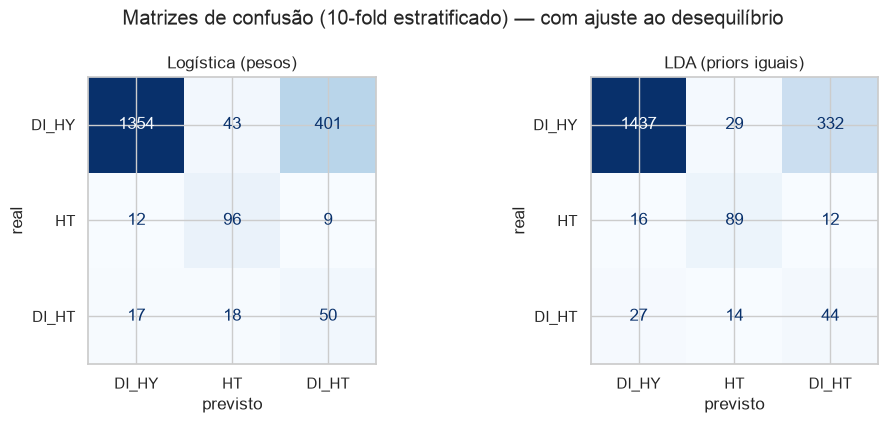

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,precision_DI_HT,n_previstos_DI_HT
Logística,0.600,0.578,0.931,0.989,0.675,0.071,0.400,15.000
LDA,0.655,0.616,0.933,0.985,0.675,0.188,0.533,30.000
Logística (pesos),0.579,0.721,0.750,0.753,0.821,0.588,0.109,460.000
LDA (priors iguais),0.593,0.693,0.785,0.799,0.761,0.518,0.113,388.000


In [6]:
show_confusions(['Logística (pesos)', 'LDA (priors iguais)'], cv_preds,
                'Matrizes de confusão (10-fold estratificado) — com ajuste ao desequilíbrio')
versions = pd.DataFrame({n: metrics(y, p) for n, p in cv_preds.items()}).T
for n, p in cv_preds.items():
    versions.loc[n, 'precision_DI_HT'] = precision_score(y, p, labels=['DI_HT'], average='macro', zero_division=0)
    versions.loc[n, 'n_previstos_DI_HT'] = (p == 'DI_HT').sum()
versions

**Conclusões:** as versões ajustadas detetam muito mais pacientes das classes minoritárias, mas pagam um preço.

| | F1 macro | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` | Precision `DI_HT` | Nº previstos `DI_HT` |
|---|---|---|---|---|---|---|---|---|
| Logística | 0.600 | 0.578 | 0.931 | 0.989 | 0.675 | 0.071 | 0.400 | 15 |
| LDA | **0.655** | 0.616 | **0.933** | 0.985 | 0.675 | 0.188 | **0.533** | 30 |
| Logística (pesos) | 0.579 | **0.721** | 0.750 | 0.753 | **0.821** | **0.588** | 0.109 | 460 |
| LDA (priors iguais) | 0.593 | 0.693 | 0.785 | 0.799 | 0.761 | 0.518 | 0.113 | 388 |

- **Ganho:** o recall de `DI_HT` passa de 0.07 para **0.59** (Logística) e de 0.19 para **0.52** (LDA). O de `HT`
  também sobe. A *balanced accuracy* melhora muito (0.58 → 0.72 e 0.62 → 0.69).
- **Custo:** para encontrar mais `DI_HT`, os modelos passam a classificar como `DI_HT` muitos pacientes que são
  `DI_HY`. A Logística prevê 460 `DI_HT` quando só existem 85. A **precision de `DI_HT` cai para ≈ 0.11** (só 1 em
  cada 9 previsões `DI_HT` está certa) e a *accuracy* desce para 0.75–0.79.
- O **F1 macro desce ligeiramente**, porque combina recall e precision: o ganho no recall das minoritárias é
  anulado pela queda da precision de `DI_HT` e do recall de `DI_HY`.

**Justificação — porque é que não há "almoços grátis"?** As classes `DI_HT` e `DI_HY` sobrepõem-se muito (EDA, 3.5 e
3.7). Mudar os pesos ou as priors **não cria informação nova**: apenas desloca a fronteira de decisão. Na zona de
sobreposição, ou se perdem os `DI_HT` (versões sem ajuste) ou se apanham juntamente com muitos `DI_HY` (versões
ajustadas). É o mesmo compromisso que os slides T3 (38) mostram ao baixar o limiar de decisão no dataset Default.

**Qual versão é melhor?** Depende do que custa mais errar:
- se o objetivo for **não deixar escapar** pacientes `DI_HT`/`HT` (rastreio), as versões ajustadas são preferíveis;
- se o objetivo for **não dar falsos diagnósticos**, as versões sem ajuste são preferíveis.

Como o desequilíbrio é a característica central deste problema, e o enunciado pede métricas adequadas, **comparamos
sempre os dois métodos nas duas versões** nas secções seguintes.

### 2.4 Que versão usar? Comparação com significância estatística

As diferenças entre versões podem ser pequenas. Para saber se são **reais** ou fruto de quais pacientes calharam em
cada fold, seguimos os slides T4 (31–33): obtemos o F1 macro e a *balanced accuracy* em **cada um dos 10 folds**,
com as **mesmas partições** para todos os modelos, e aplicamos um **teste *t* emparelhado** entre modelos.

In [7]:
fold_scores = {}
for n, m in MODELS.items():
    r = cross_validate(m, X, y, cv=CV10, scoring={'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy'})
    fold_scores[n] = pd.DataFrame({'f1_macro': r['test_f1_macro'], 'bal_acc': r['test_bal_acc']})

summary = pd.DataFrame({n: {'F1 macro (média)': s.f1_macro.mean(), 'F1 macro (dp)': s.f1_macro.std(),
                            'Bal. acc. (média)': s.bal_acc.mean(), 'Bal. acc. (dp)': s.bal_acc.std()}
                        for n, s in fold_scores.items()}).T
display(summary)

pairs = [('LDA', 'Logística'), ('LDA (priors iguais)', 'Logística (pesos)'),
         ('Logística (pesos)', 'Logística'), ('LDA (priors iguais)', 'LDA')]
tests = []
for a, b in pairs:
    for met in ('f1_macro', 'bal_acc'):
        d = fold_scores[a][met] - fold_scores[b][met]
        tests.append({'comparação': f'{a}  vs  {b}', 'métrica': met, 'diferença média': d.mean(),
                      'folds em que A > B': f'{(d > 0).sum()}/10', 'p-value (t emparelhado)': stats.ttest_rel(
                          fold_scores[a][met], fold_scores[b][met]).pvalue})
pd.DataFrame(tests)

,F1 macro (média),F1 macro (dp),Bal. acc. (média),Bal. acc. (dp)
Logística,0.596,0.044,0.578,0.032
LDA,0.650,0.046,0.615,0.040
Logística (pesos),0.579,0.036,0.723,0.051
LDA (priors iguais),0.594,0.042,0.694,0.048


,comparação,métrica,diferença média,folds em que A > B,p-value (t emparelhado)
0,LDA vs Logística,f1_macro,0.054,7/10,0.043
1,LDA vs Logística,bal_acc,0.037,7/10,0.079
2,LDA (priors iguais) vs Logística (pesos),f1_macro,0.015,6/10,0.285
3,LDA (priors iguais) vs Logística (pesos),bal_acc,-0.029,2/10,0.135
4,Logística (pesos) vs Logística,f1_macro,-0.017,3/10,0.276
5,Logística (pesos) vs Logística,bal_acc,0.144,10/10,0.000
6,LDA (priors iguais) vs LDA,f1_macro,-0.056,1/10,0.041
7,LDA (priors iguais) vs LDA,bal_acc,0.078,8/10,0.015


**Conclusões:**

| Comparação | F1 macro | Balanced accuracy |
|---|---|---|
| **LDA vs Logística** (sem ajuste) | LDA +0.054, melhor em 7/10 folds, **p = 0.043** | LDA +0.037, 7/10 folds, p = 0.079 |
| **LDA (priors iguais) vs Logística (pesos)** | LDA +0.015, 6/10 folds, p = 0.285 | Logística +0.029, 8/10 folds, p = 0.135 |
| Logística (pesos) vs Logística | −0.017, p = 0.276 | **+0.144, 10/10 folds, p < 0.001** |
| LDA (priors iguais) vs LDA | **−0.056, p = 0.041** | **+0.078, p = 0.015** |

- **Sem ajuste, a LDA é significativamente melhor que a Logística no F1 macro** (p = 0.043) e tende a sê-lo na
  *balanced accuracy* (p = 0.079).
- **Com ajuste, os dois métodos ficam estatisticamente empatados**: a LDA tem um F1 macro ligeiramente superior e a
  Logística uma *balanced accuracy* ligeiramente superior, mas nenhuma das diferenças é significativa (p > 0.1).
- **O ajuste ao desequilíbrio** melhora sempre de forma significativa a *balanced accuracy* (a Logística melhora nos 10
  folds), à custa de uma pequena descida do F1 macro.

**Justificação:** um teste emparelhado compara os dois modelos **nos mesmos folds**, eliminando a variabilidade que
vem de quais pacientes calharam em cada fold. Por isso consegue detetar diferenças que as médias sozinhas não
mostram. Os desvios padrão entre folds (0.036–0.051) são da mesma ordem das diferenças entre modelos, e é por isso que
algumas diferenças não são significativas. Como os 10 folds partilham dados de treino, não são totalmente
independentes, e os p-values devem ser lidos como indicativos (slide T4, 33).

## 3. Métodos de reamostragem

O enunciado pede quatro formas de estimar o desempenho em pacientes novos. Todas respondem à mesma pergunta (*"que
desempenho terá o modelo em dados que nunca viu?"*), mas de maneiras diferentes, com **custo, enviesamento e
variância** diferentes (slides T4, 6–10 e 40).

| Método | Treino em cada repetição | Teste | Nº de modelos |
|---|---|---|---|
| *Holdout* | 70% (1400) | 30% (600), uma vez | 1 |
| *k-fold* (k = 5 / 10) | (k−1)/k dos dados (1600 / 1800) | cada fold uma vez | 5 / 10 |
| LOOCV | 1999 | 1 paciente, 2000 vezes | 2000 |
| *Bootstrap* OOB | 2000 sorteados com reposição (~63% distintos) | os ~37% que ficaram de fora | 200 |

**Cuidados comuns a todos os métodos:**
- a padronização (`StandardScaler`) está dentro de um *pipeline*, por isso é ajustada **apenas com os dados de treino
  de cada repetição**. Ajustá-la com todos os dados deixaria passar informação do teste para o treino;
- sempre que possível usamos **estratificação**, para que todas as classes estejam representadas no teste;
- avaliamos os **quatro modelos** da secção 2 com todos os métodos.

### 3.1 *Holdout* (método do conjunto de validação)

**Como funciona (slide T4, 19):** divide-se os dados uma vez em treino (70%) e teste (30%); o modelo aprende no
treino e é avaliado no teste. Usamos divisão **estratificada**, para que as 3 classes apareçam no teste nas mesmas
proporções que no dataset: com só 85 `DI_HT`, uma divisão não estratificada podia deixar o teste com muito poucos.

Mostramos o relatório completo (`classification_report`, como no slide T3, 37) para os quatro modelos.

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print('Teste:', y_te.value_counts().to_dict())
holdout = {}
for n, m in MODELS.items():
    pred = clone(m).fit(X_tr, y_tr).predict(X_te)
    holdout[n] = metrics(y_te, pred)
    if n in ('Logística (pesos)', 'LDA (priors iguais)'):
        print(f'\n=== {n} ===')
        print(classification_report(y_te, pred, labels=CLASSES, digits=3, zero_division=0))
pd.DataFrame(holdout).T

Teste: {'DI_HY': 539, 'HT': 35, 'DI_HT': 26}

=== Logística (pesos) ===
              precision    recall  f1-score   support

       DI_HY      0.971     0.798     0.876       539
          HT      0.525     0.914     0.667        35
       DI_HT      0.073     0.269     0.115        26

    accuracy                          0.782       600
   macro avg      0.523     0.660     0.552       600
weighted avg      0.906     0.782     0.831       600


=== LDA (priors iguais) ===
              precision    recall  f1-score   support

       DI_HY      0.967     0.863     0.912       539
          HT      0.600     0.857     0.706        35
       DI_HT      0.116     0.308     0.168        26

    accuracy                          0.838       600
   macro avg      0.561     0.676     0.595       600
weighted avg      0.908     0.838     0.868       600



,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logística,0.578,0.605,0.935,0.987,0.829,0.000
LDA,0.614,0.602,0.932,0.985,0.743,0.077
Logística (pesos),0.552,0.660,0.782,0.798,0.914,0.269
LDA (priors iguais),0.595,0.676,0.838,0.863,0.857,0.308


**Conclusões:** o conjunto de teste tem 539 `DI_HY`, 35 `HT` e só **26 `DI_HT`**.

| | F1 macro | Bal. acc. | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|
| Logística | 0.578 | 0.605 | 0.829 | **0.000** |
| LDA | 0.614 | 0.602 | 0.743 | 0.077 |
| Logística (pesos) | 0.552 | 0.660 | 0.914 | 0.269 |
| LDA (priors iguais) | **0.595** | **0.676** | 0.857 | **0.308** |

- Os relatórios mostram o mesmo padrão da secção 2: `DI_HY` e `HT` são bem identificadas (F1 de 0.88–0.91 e
  0.67–0.71), e **`DI_HT` é a classe problemática** (F1 0.12–0.17, precision 0.07–0.12).
- A Logística sem ajuste **não identifica nenhum dos 26 `DI_HT`** do teste.
- Neste *holdout* em particular, a LDA com priors iguais é a melhor nas duas métricas principais.

**Justificação — porque desconfiar de um único *holdout*?** Os resultados diferem dos da validação cruzada (por
exemplo, o recall de `DI_HT` da Logística (pesos) é 0.27 aqui contra 0.59 em 10-fold). Com só 26 `DI_HT` no teste,
**cada paciente `DI_HT` acertado ou falhado muda o recall em ~4 pontos percentuais**. A estimativa depende muito de
quais pacientes calharam no teste, o que medimos a seguir.

### 3.2 Quanto varia o *holdout*? Repetir a divisão 100 vezes

O resultado de um *holdout* depende de **quais** pacientes calharam no teste. Os slides (T4, 20 e 36–37) mostram
que a estimativa tem variância: com outra divisão, o resultado muda. Para medir essa variância, repetimos o *holdout*
estratificado com **100 sementes diferentes** e vemos como se distribuem as métricas.

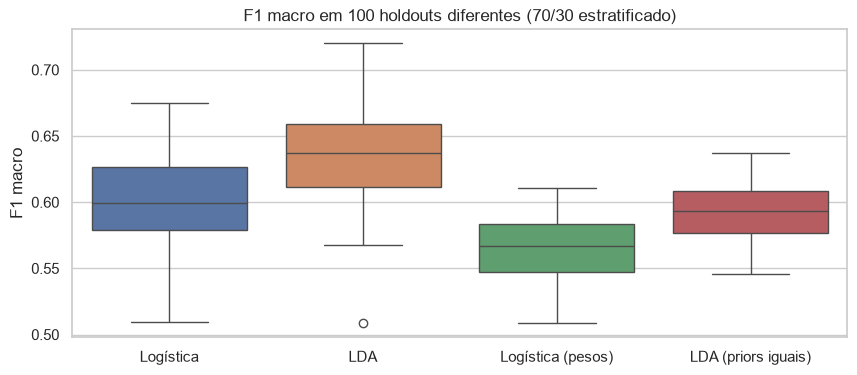

,média,dp,mín,máx,recall DI_HT dp
Logística,0.602,0.034,0.509,0.675,0.049
LDA,0.636,0.036,0.508,0.720,0.062
Logística (pesos),0.565,0.024,0.509,0.611,0.104
LDA (priors iguais),0.592,0.020,0.545,0.637,0.104


In [9]:
def repeated_holdout(model, n_rep=100, test_size=0.30):
    out = []
    for s in range(n_rep):
        a, b, c, d = train_test_split(X, y, test_size=test_size, stratify=y, random_state=s)
        out.append(metrics(d, clone(model).fit(a, c).predict(b)))
    return pd.DataFrame(out)

rep_holdout = {n: repeated_holdout(MODELS[n]) for n in MODELS}
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame({n: r.f1_macro for n, r in rep_holdout.items()}), ax=ax)
ax.set_ylabel('F1 macro'); ax.set_title('F1 macro em 100 holdouts diferentes (70/30 estratificado)')
plt.show()
pd.DataFrame({n: {'média': r.f1_macro.mean(), 'dp': r.f1_macro.std(), 'mín': r.f1_macro.min(),
                  'máx': r.f1_macro.max(), 'recall DI_HT dp': r.recall_DI_HT.std()}
              for n, r in rep_holdout.items()}).T

**Conclusões:** repetir o *holdout* 100 vezes mostra que **a mesma metodologia dá resultados muito diferentes
consoante a divisão**:

| | F1 macro médio | Desvio padrão | Mínimo | Máximo | dp do recall `DI_HT` |
|---|---|---|---|---|---|
| Logística | 0.602 | 0.034 | 0.509 | 0.675 | 0.049 |
| LDA | 0.636 | 0.036 | 0.508 | 0.720 | 0.062 |
| Logística (pesos) | 0.565 | 0.024 | 0.509 | 0.611 | **0.104** |
| LDA (priors iguais) | 0.592 | **0.020** | 0.545 | 0.637 | **0.104** |

- O F1 macro da LDA varia entre **0.51 e 0.72** consoante a divisão: uma diferença de 0.21 só por acaso.
- O recall de `DI_HT` tem um desvio padrão de **0.10**: numa divisão pode ser 0.3 e noutra 0.6.
- O *holdout* único da secção 3.1 (por exemplo 0.552 para a Logística (pesos)) está **abaixo da média** das 100
  repetições (0.565). Se só tivéssemos feito essa divisão, teríamos subestimado o modelo.

**Justificação — de onde vem esta variância?**
1. **Teste pequeno para as classes raras:** só ~26 `DI_HT` e ~35 `HT` em cada teste, por isso poucos pacientes mudam
   muito as métricas por classe.
2. **Treino reduzido:** o modelo aprende com 70% dos dados, ou seja, só ~60 `DI_HT`. Divisões diferentes produzem
   modelos diferentes.
3. **Uma única medição:** não há média de várias avaliações para "suavizar" o acaso.

Curiosamente, as versões ajustadas têm um F1 macro **mais estável** (dp 0.020–0.024) do que as não ajustadas
(0.034–0.036). Sem ajuste, o F1 de `DI_HT` depende de acertar em poucos casos, e oscila entre perto de 0 e valores
razoáveis de divisão para divisão.

### 3.3 Validação cruzada *k-fold* (k = 5 e k = 10)

**Como funciona (slides T4, 21–26):** os dados são divididos em *k* partes (*folds*); cada fold serve uma vez de teste
enquanto os outros *k−1* treinam o modelo. Cada paciente é testado **exatamente uma vez**. Usamos a versão
**estratificada** (slide 26): com classes desequilibradas, cada fold mantém as proporções das classes.

Há **duas formas de variância** a distinguir:
1. **Entre folds:** quanto variam as *k* métricas dentro de uma mesma validação cruzada;
2. **Da estimativa:** quanto muda a **média** final se repetirmos a validação cruzada com outra partição aleatória.
   Repetimos 20 vezes, com 20 sementes.

In [10]:
def repeated_kfold(model, k, n_rep=20):
    fold_level, means = [], []
    for s in range(n_rep):
        cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=s)
        r = cross_validate(model, X, y, cv=cv, scoring={'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy'})
        fold_level.append(r['test_f1_macro'])
        means.append({'f1_macro': r['test_f1_macro'].mean(), 'bal_acc': r['test_bal_acc'].mean()})
    return np.concatenate(fold_level), pd.DataFrame(means)

kfold = {}
for k in (5, 10):
    for n in MODELS:
        folds, means = repeated_kfold(MODELS[n], k)
        kfold[(k, n)] = {'folds': folds, 'means': means}

kfold_table = pd.DataFrame({f'{k}-fold | {n}': {
    'F1 macro (estimativa)': v['means'].f1_macro.mean(),
    'dp entre folds': v['folds'].std(),
    'dp da estimativa (20 repetições)': v['means'].f1_macro.std(),
    'Bal. acc. (estimativa)': v['means'].bal_acc.mean()} for (k, n), v in kfold.items()}).T
kfold_table

,F1 macro (estimativa),dp entre folds,dp da estimativa (20 repetições),Bal. acc. (estimativa)
5-fold | Logística,0.604,0.038,0.011,0.584
5-fold | LDA,0.642,0.049,0.010,0.609
5-fold | Logística (pesos),0.572,0.027,0.007,0.706
5-fold | LDA (priors iguais),0.589,0.028,0.006,0.684
10-fold | Logística,0.607,0.058,0.011,0.588
10-fold | LDA,0.645,0.069,0.007,0.614
10-fold | Logística (pesos),0.577,0.039,0.004,0.714
10-fold | LDA (priors iguais),0.590,0.041,0.006,0.686


**Conclusões:**

| | Estimativa F1 macro | dp entre folds | dp da estimativa (20 rep.) | Bal. acc. |
|---|---|---|---|---|
| 5-fold · Logística (pesos) | 0.572 | 0.027 | 0.007 | 0.706 |
| 5-fold · LDA (priors iguais) | 0.589 | 0.028 | 0.006 | 0.684 |
| 10-fold · Logística (pesos) | 0.577 | 0.039 | **0.004** | 0.714 |
| 10-fold · LDA (priors iguais) | 0.590 | 0.041 | 0.006 | 0.686 |
| 10-fold · LDA (sem ajuste) | **0.645** | 0.069 | 0.007 | 0.614 |

1. **A estimativa da validação cruzada é muito mais estável que a do *holdout*.** Repetindo com outra partição, a
   média do 10-fold muda apenas 0.004–0.011 (desvio padrão), contra 0.020–0.036 no *holdout*: uma redução de
   **3 a 6 vezes**. Isto acontece porque a média de *k* avaliações cancela grande parte do acaso, e porque **todos
   os pacientes são usados como teste** uma vez.
2. **A variabilidade entre folds é maior com k = 10 do que com k = 5** (por exemplo 0.039 vs 0.027). Com k = 10, cada
   fold de teste tem só ~200 pacientes e ~8–9 `DI_HT`, por isso cada avaliação individual é mais "ruidosa".
3. **Ainda assim, a estimativa final é igual ou mais estável com k = 10**, porque é a média de mais avaliações.
4. **A estimativa sobe ligeiramente de k = 5 para k = 10** (0.572 → 0.577 na Logística (pesos)). Com k = 10 o modelo
   treina com 1800 pacientes em vez de 1600, e aprende um pouco melhor as classes raras: o k = 5 é ligeiramente mais
   **pessimista**.
5. **A ordem dos modelos mantém-se:** LDA > Logística no F1 macro, Logística (pesos) > LDA (priors iguais) na
   *balanced accuracy*.

### 3.4 *Leave-One-Out* (LOOCV)

**Como funciona (slide T4, 27):** é o caso extremo do *k-fold*, com *k = N* = 2000. Treina-se o modelo 2000 vezes,
sempre com 1999 pacientes, e testa-se no paciente que ficou de fora.

Duas particularidades importantes:
- cada fold tem **um só paciente**, por isso o "F1 de cada fold" não existe (com uma previsão só se pode acertar ou
  errar). As métricas calculam-se juntando as 2000 previsões;
- o LOOCV é **determinístico**: só há uma forma de deixar um paciente de fora de cada vez, logo repetir dá sempre o
  mesmo resultado. Também não pode ser estratificado.

In [11]:
loo_preds, loo_time = {}, {}
for n, m in MODELS.items():
    t0 = time.time()
    loo_preds[n] = cross_val_predict(m, X, y, cv=LeaveOneOut(), n_jobs=-1)
    loo_time[n] = time.time() - t0
loo_table = pd.DataFrame({n: {**metrics(y, p), 'tempo (s)': loo_time[n], 'nº de modelos treinados': len(y)}
                          for n, p in loo_preds.items()}).T
loo_table

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,tempo (s),nº de modelos treinados
Logística,0.616,0.589,0.934,0.990,0.684,0.094,7.265,2000.000
LDA,0.660,0.620,0.934,0.986,0.675,0.200,3.384,2000.000
Logística (pesos),0.586,0.724,0.755,0.759,0.812,0.600,5.989,2000.000
LDA (priors iguais),0.586,0.684,0.779,0.794,0.752,0.506,3.223,2000.000


**Conclusões:**

| | F1 macro | Bal. acc. | Recall `DI_HT` | Tempo |
|---|---|---|---|---|
| Logística | 0.616 | 0.589 | 0.094 | 5.5 s |
| LDA | **0.660** | 0.620 | 0.200 | 2.6 s |
| Logística (pesos) | 0.586 | **0.724** | **0.600** | 4.7 s |
| LDA (priors iguais) | 0.586 | 0.684 | 0.506 | 2.5 s |

- O LOOCV dá as estimativas **mais altas** de todos os métodos, para quase todos os modelos (por exemplo LDA 0.660 vs
  0.645 em 10-fold e 0.636 no *holdout*). Cada modelo treina com 1999 pacientes, quase o dataset completo, por isso
  é o método **menos pessimista (menos enviesado)**.
- As conclusões são as mesmas: sem ajuste a LDA é melhor; com ajuste há empate no F1 macro (0.586 = 0.586) e a
  Logística ganha na *balanced accuracy*.
- O custo foi baixo (2.5–5.5 s, com processamento paralelo), porque estes modelos são rápidos de treinar. Com modelos
  mais pesados, 2000 ajustes por modelo seriam proibitivos (slide T4, 39–40).

**Variância do LOOCV:**
- **Repetir o LOOCV dá sempre o mesmo resultado** (variância de partição = 0): só há uma forma de deixar cada
  paciente de fora.
- No entanto, **isto não significa que a estimativa seja precisa**. Os 2000 modelos são quase idênticos (diferem em
  um paciente), por isso os seus erros estão muito correlacionados. Segundo a teoria (ISLP, 5.1.4; slide T4, 40), a
  estimativa do LOOCV tem **variância elevada em relação ao verdadeiro erro**: se tivéssemos recolhido outros 2000
  pacientes, o resultado do LOOCV podia mudar bastante.
- Também **não é possível estratificar** e não há "métrica por fold" (cada fold tem um único paciente), por isso não
  há forma de medir a dispersão a partir dos próprios resultados.

### 3.5 *Bootstrap* com avaliação *out-of-bag* (OOB)

**Como funciona (slides T4, 41–46, e o exemplo das aulas):** em cada iteração tira-se uma amostra **com reposição**
do mesmo tamanho do dataset (2000). Alguns pacientes aparecem repetidos e outros ficam de fora; a probabilidade de um
paciente ficar de fora é $(1 - 1/N)^N \approx e^{-1} \approx 36.8\%$. O modelo treina com a amostra *bootstrap* e é
avaliado nos pacientes que ficaram de fora (*out-of-bag*), que nunca viu.

Repetimos **200 vezes** (como no exemplo das aulas) e obtemos a distribuição das métricas, a média, o desvio padrão e
um intervalo de confiança a 95% (percentis 2.5 e 97.5).

In [12]:
def bootstrap_oob(model, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(y))
    out = []
    for _ in range(B):
        inb = rng.choice(idx_all, size=len(y), replace=True)
        oob = np.setdiff1d(idx_all, inb)
        m = clone(model).fit(X.iloc[inb], y.iloc[inb])
        out.append({**metrics(y.iloc[oob], m.predict(X.iloc[oob])), 'oob_frac': len(oob) / len(y),
                    'n_DI_HT_oob': (y.iloc[oob] == 'DI_HT').sum()})
    return pd.DataFrame(out)

boot = {n: bootstrap_oob(MODELS[n]) for n in MODELS}
boot_table = pd.DataFrame({n: {'F1 macro (média)': b.f1_macro.mean(), 'dp': b.f1_macro.std(),
                               'IC95% inf': b.f1_macro.quantile(.025), 'IC95% sup': b.f1_macro.quantile(.975),
                               'Bal. acc. (média)': b.bal_acc.mean(), 'fração OOB média': b.oob_frac.mean(),
                               'nº DI_HT no OOB (média)': b.n_DI_HT_oob.mean()} for n, b in boot.items()}).T
boot_table

,F1 macro (média),dp,IC95% inf,IC95% sup,Bal. acc. (média),fração OOB média,nº DI_HT no OOB (média)
Logística,0.613,0.031,0.558,0.684,0.592,0.367,30.565
LDA,0.638,0.028,0.582,0.687,0.605,0.367,30.565
Logística (pesos),0.560,0.023,0.518,0.604,0.695,0.367,30.565
LDA (priors iguais),0.595,0.021,0.554,0.634,0.689,0.367,30.565


**Conclusões:**

| | F1 macro médio | dp | IC95% | Bal. acc. |
|---|---|---|---|---|
| Logística | 0.613 | 0.031 | [0.558, 0.684] | 0.592 |
| LDA | **0.638** | 0.028 | [0.582, 0.687] | 0.605 |
| Logística (pesos) | 0.560 | 0.023 | [0.518, 0.604] | **0.695** |
| LDA (priors iguais) | 0.595 | **0.021** | [0.554, 0.634] | 0.689 |

- A fração média de pacientes *out-of-bag* é **0.367**, exatamente o valor teórico $e^{-1} \approx 0.368$
  (slide T4, 45). Cada conjunto OOB tem em média ~31 `DI_HT`.
- O *bootstrap* devolve uma **distribuição completa** e um **intervalo de confiança** para o desempenho. Os
  intervalos da LDA e da Logística sobrepõem-se bastante, o que confirma que as diferenças entre os dois métodos são
  modestas.
- As estimativas são **mais baixas** do que as do 10-fold e do LOOCV, sobretudo para a Logística (pesos): 0.560 contra
  0.577 (10-fold) e 0.586 (LOOCV).

**Justificação — porque é que o *bootstrap* é pessimista?** Cada amostra *bootstrap* tem 2000 pacientes, mas só ~63%
são **distintos** (os outros são repetições). O modelo aprende, na prática, com ~1264 pacientes diferentes, menos que
no 5-fold (1600). Isto afeta mais a Logística, que precisa de exemplos variados das classes raras para estimar os
seus coeficientes. A LDA, que só precisa de médias e de uma covariância comum, é menos afetada (0.595 vs 0.590 no
10-fold).

## 4. Como é que o método de reamostragem afeta a variância?

Esta é a pergunta central do enunciado: *"indicate how the variance is affected by the resampling methods used"*.
Juntamos aqui os resultados das secções 3.1–3.5.

### 4.1 Comparação lado a lado

Para cada método e modelo mostramos:
- a **estimativa** do F1 macro;
- a **variabilidade das avaliações individuais** (entre divisões, folds ou iterações);
- a **variabilidade da estimativa final** (quanto muda a estimativa se o procedimento for repetido);
- o **custo** (nº de modelos treinados).

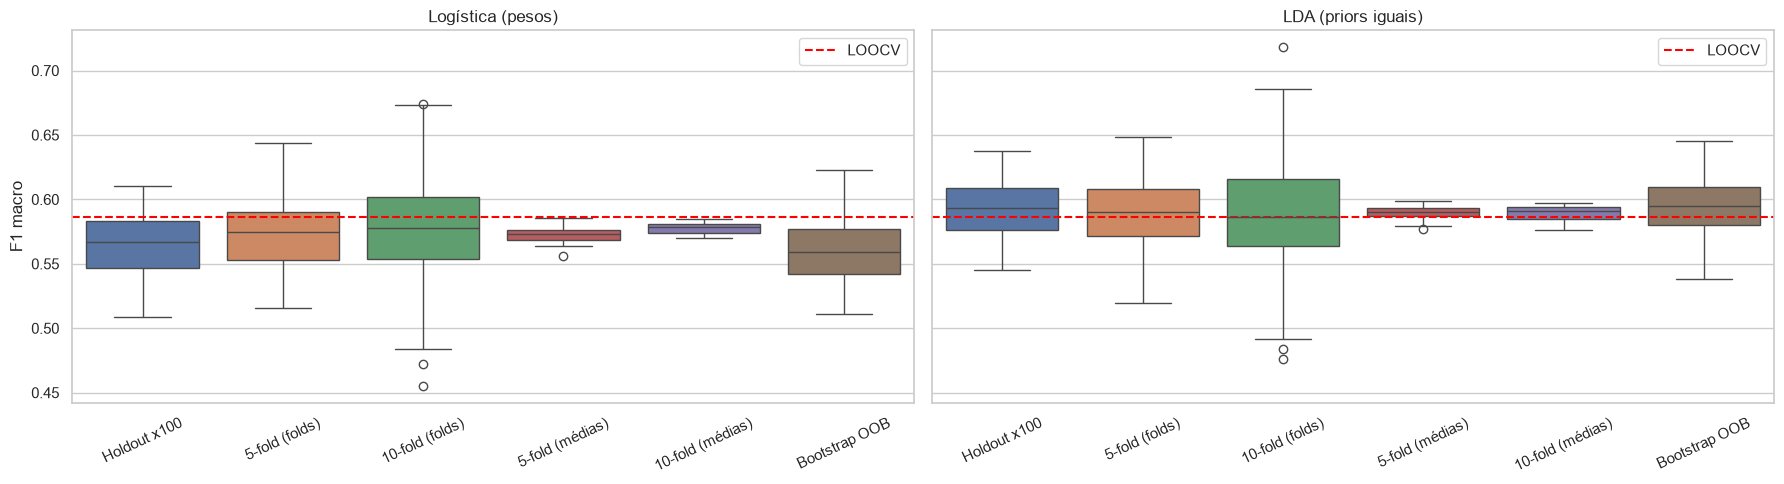

F1 macro  dp das avaliações  \
modelo              método                                               
Logística (pesos)   Holdout (1 divisão)       0.552                NaN   
                    5-fold estratificado      0.572              0.027   
                    10-fold estratificado     0.577              0.039   
                    LOOCV                     0.586                NaN   
                    Bootstrap OOB (B=200)     0.560              0.023   
LDA (priors iguais) Holdout (1 divisão)       0.595                NaN   
                    5-fold estratificado      0.589              0.028   
                    10-fold estratificado     0.590              0.041   
                    LOOCV                     0.586                NaN   
                    Bootstrap OOB (B=200)     0.595              0.021   

                                           dp da estimativa  nº modelos  
modelo              método                                               
Logística (pesos)   Holdout (1 divisão)               0.024           1  
                    5-fold estratificado              0.007           5  
                    10-fold estratificado             0.004          10  
                    LOOCV                             0.000        2000  
                    Bootstrap OOB (B=200)             0.002         200  
LDA (priors iguais) Holdout (1 divisão)               0.020           1  
                    5-fold estratificado              0.006           5  
                    10-fold estratificado             0.006          10  
                    LOOCV                             0.000        2000  
                    Bootstrap OOB (B=200)             0.001         200

In [13]:
rows = []
for n in MODELS:
    rows.append({'modelo': n, 'método': 'Holdout (1 divisão)', 'F1 macro': holdout[n]['f1_macro'],
                 'dp das avaliações': np.nan, 'dp da estimativa': rep_holdout[n].f1_macro.std(), 'nº modelos': 1})
    for k in (5, 10):
        v = kfold[(k, n)]
        rows.append({'modelo': n, 'método': f'{k}-fold estratificado', 'F1 macro': v['means'].f1_macro.mean(),
                     'dp das avaliações': v['folds'].std(), 'dp da estimativa': v['means'].f1_macro.std(), 'nº modelos': k})
    rows.append({'modelo': n, 'método': 'LOOCV', 'F1 macro': loo_table.loc[n, 'f1_macro'],
                 'dp das avaliações': np.nan, 'dp da estimativa': 0.0, 'nº modelos': len(y)})
    rows.append({'modelo': n, 'método': 'Bootstrap OOB (B=200)', 'F1 macro': boot[n].f1_macro.mean(),
                 'dp das avaliações': boot[n].f1_macro.std(),
                 'dp da estimativa': boot[n].f1_macro.std() / np.sqrt(len(boot[n])), 'nº modelos': 200})
variance = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, n in zip(axes, ['Logística (pesos)', 'LDA (priors iguais)']):
    dist = pd.DataFrame({'Holdout x100': rep_holdout[n].f1_macro,
                         '5-fold (folds)': pd.Series(kfold[(5, n)]['folds']),
                         '10-fold (folds)': pd.Series(kfold[(10, n)]['folds']),
                         '5-fold (médias)': kfold[(5, n)]['means'].f1_macro,
                         '10-fold (médias)': kfold[(10, n)]['means'].f1_macro,
                         'Bootstrap OOB': boot[n].f1_macro})
    sns.boxplot(data=dist, ax=ax); ax.axhline(loo_table.loc[n, 'f1_macro'], color='red', ls='--', label='LOOCV')
    ax.set_title(n); ax.tick_params(axis='x', rotation=25); ax.legend()
axes[0].set_ylabel('F1 macro')
plt.tight_layout(); plt.show()
variance[variance.modelo.isin(['Logística (pesos)', 'LDA (priors iguais)'])].set_index(['modelo', 'método'])

**Conclusões (versões ajustadas; as versões sem ajuste seguem o mesmo padrão):**

| Método | Estimativa F1 (Log. pesos / LDA priors) | dp das avaliações | **dp da estimativa** | Nº modelos |
|---|---|---|---|---|
| *Holdout* (1 divisão) | 0.552 / 0.595 | — | **0.024 / 0.020** | 1 |
| 5-fold estratificado | 0.572 / 0.589 | 0.027 / 0.028 | 0.007 / 0.006 | 5 |
| 10-fold estratificado | 0.577 / 0.590 | 0.039 / 0.041 | 0.004 / 0.006 | 10 |
| LOOCV | 0.586 / 0.586 | — | 0 (determinístico) | 2000 |
| *Bootstrap* OOB (B = 200) | 0.560 / 0.595 | 0.023 / 0.021 | 0.002 / 0.001 | 200 |

*O "dp da estimativa" do bootstrap é o erro padrão da média das 200 iterações ($dp/\sqrt{200}$).*

**Como é que o método de reamostragem afeta a variância?**

1. ***Holdout*: a estimativa com mais variância.** É uma única medição num teste de 600 pacientes com ~26 `DI_HT`. A
   divisão sozinha pode mudar o F1 macro em ±0.04–0.05 (dois desvios padrão). Como vimos, o *holdout* único ficou
   abaixo da média das repetições.
2. ***k-fold*: variância muito menor**, porque cada paciente é testado uma vez e o resultado é a média de *k*
   avaliações. A estimativa é **3 a 6 vezes mais estável** do que a do *holdout*. Cada fold individual varia mais
   com *k* maior (folds de teste mais pequenos), mas a média fica mais estável.
3. **LOOCV: sem variância de partição** (é determinístico), mas os 2000 modelos treinados são quase iguais e os seus
   erros estão correlacionados. A estimativa tem pouco enviesamento, mas **variância elevada em relação ao verdadeiro
   erro**, e não pode ser medida a partir dos próprios resultados.
4. ***Bootstrap*: a variância de cada iteração é semelhante à de um *holdout*** (dp 0.021–0.031), mas ao fazer a média
   de 200 iterações a estimativa final fica muito estável. É o único método que dá diretamente um **intervalo de
   confiança**. O custo é ser **pessimista**, porque cada modelo treina com só ~63% de pacientes distintos.

**O gráfico** mostra isto visualmente: as caixas das avaliações individuais (*holdout* ×100, folds, *bootstrap*) são
largas, e as das **médias** do 5-fold e do 10-fold são muito estreitas. A linha do LOOCV fica no topo, refletindo o
seu menor pessimismo.

**Enviesamento:** quanto menos dados o modelo usa para treinar, mais pessimista é a estimativa. A ordem das
estimativas da Logística (pesos) segue exatamente essa lógica: *bootstrap* (~63% de pacientes distintos) 0.560 <
5-fold (80%) 0.572 < 10-fold (90%) 0.577 < LOOCV (99.95%) 0.586. O *holdout* (70%) ficou ainda mais abaixo por azar da
divisão.

### 4.2 O efeito de *k* na validação cruzada

Os slides (T4, 40) resumem o compromisso na escolha de *k*:
- ***k* pequeno** → cada modelo treina com menos dados → estimativa **pessimista** (mais enviesada), mas mais
  estável e mais barata;
- ***k* grande** (no limite, LOOCV) → treino quase com todos os dados → estimativa **pouco enviesada**, mas os
  modelos são muito parecidos entre si e o custo cresce.

Medimos, para *k* ∈ {2, 3, 5, 10, 20}, a estimativa média, a variabilidade **entre folds** e a variabilidade **da
estimativa** (10 repetições com sementes diferentes), para a versão ponderada de cada modelo.

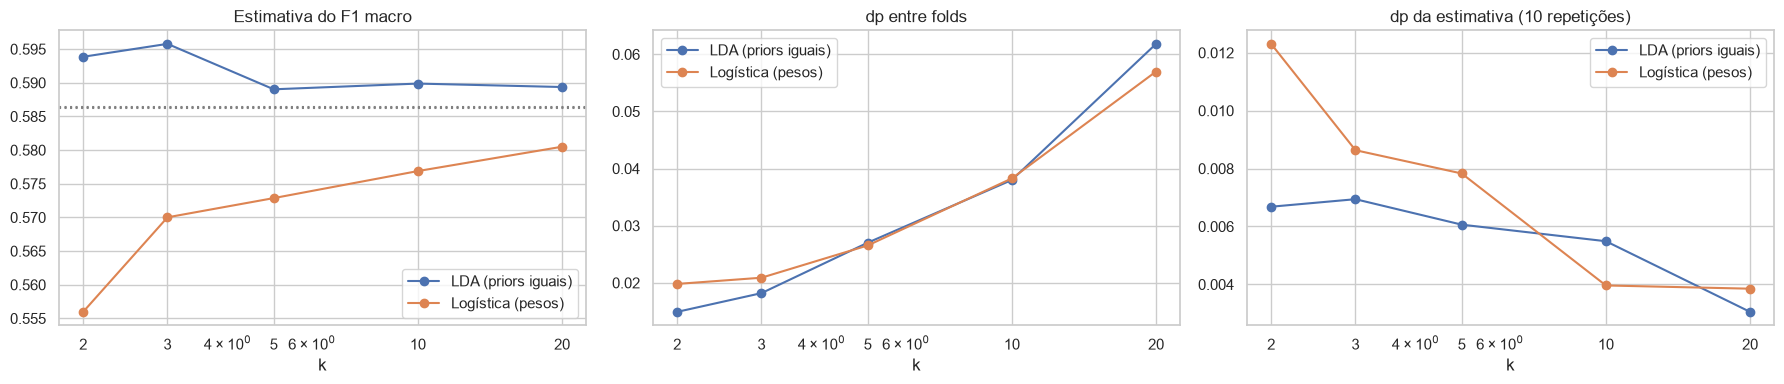

tamanho do treino  DI_HT por fold de teste  F1 macro  \
modelo              k                                                          
Logística (pesos)   2                1000                   42.500     0.556   
                    3                1333                   28.300     0.570   
                    5                1600                   17.000     0.573   
                    10               1800                    8.500     0.577   
                    20               1900                    4.200     0.580   
LDA (priors iguais) 2                1000                   42.500     0.594   
                    3                1333                   28.300     0.596   
                    5                1600                   17.000     0.589   
                    10               1800                    8.500     0.590   
                    20               1900                    4.200     0.589   

                        dp entre folds  dp da estimativa  
modelo              k                                     
Logística (pesos)   2            0.020             0.012  
                    3            0.021             0.009  
                    5            0.027             0.008  
                    10           0.038             0.004  
                    20           0.057             0.004  
LDA (priors iguais) 2            0.015             0.007  
                    3            0.018             0.007  
                    5            0.027             0.006  
                    10           0.038             0.005  
                    20           0.062             0.003

In [14]:
k_rows = []
for n in ['Logística (pesos)', 'LDA (priors iguais)']:
    for k in (2, 3, 5, 10, 20):
        folds, means = repeated_kfold(MODELS[n], k, n_rep=10)
        k_rows.append({'modelo': n, 'k': k, 'tamanho do treino': int(len(y) * (k - 1) / k),
                       'DI_HT por fold de teste': round(85 / k, 1), 'F1 macro': means.f1_macro.mean(),
                       'dp entre folds': folds.std(), 'dp da estimativa': means.f1_macro.std()})
k_effect = pd.DataFrame(k_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for n, g in k_effect.groupby('modelo'):
    axes[0].plot(g.k, g['F1 macro'], marker='o', label=n)
    axes[1].plot(g.k, g['dp entre folds'], marker='o', label=n)
    axes[2].plot(g.k, g['dp da estimativa'], marker='o', label=n)
for ax, t in zip(axes, ['Estimativa do F1 macro', 'dp entre folds', 'dp da estimativa (10 repetições)']):
    ax.set_xlabel('k'); ax.set_title(t); ax.set_xscale('log'); ax.set_xticks([2, 3, 5, 10, 20]); ax.set_xticklabels([2, 3, 5, 10, 20]); ax.legend()
for n in ['Logística (pesos)', 'LDA (priors iguais)']:
    axes[0].axhline(loo_table.loc[n, 'f1_macro'], ls=':', color='grey')
plt.tight_layout(); plt.show()
k_effect.set_index(['modelo', 'k'])

**Conclusões:**

| k | Treino | `DI_HT` por fold | F1 Log. (pesos) | F1 LDA (priors) | dp entre folds | dp da estimativa |
|---|---|---|---|---|---|---|
| 2 | 1000 | 42.5 | 0.556 | 0.594 | 0.020 / 0.015 | **0.012 / 0.007** |
| 5 | 1600 | 17.0 | 0.573 | 0.589 | 0.027 / 0.027 | 0.008 / 0.006 |
| 10 | 1800 | 8.5 | 0.577 | 0.590 | 0.038 / 0.038 | 0.004 / 0.005 |
| 20 | 1900 | 4.2 | 0.580 | 0.589 | **0.057 / 0.062** | **0.004 / 0.003** |

1. **Enviesamento:** a estimativa da Logística (pesos) **sobe com *k*** (0.556 → 0.580), aproximando-se do LOOCV
   (0.586). Com k = 2 o modelo treina só com metade dos dados, e o desempenho é subestimado. A LDA é praticamente
   insensível a *k* (0.589–0.596): estima poucos parâmetros (médias e uma covariância comum), por isso aprende quase
   o mesmo com 1000 ou com 1900 pacientes.
2. **Variância entre folds:** **aumenta** com *k* (0.015–0.020 → 0.057–0.062). Com k = 20, cada fold de teste tem
   apenas ~4 `DI_HT`, e um único paciente acertado ou falhado muda muito o F1 desse fold.
3. **Variância da estimativa:** **diminui** com *k* (0.012 → 0.004 na Logística). A média de muitos folds é mais
   estável do que a média de poucos, e os modelos treinados com mais dados são mais parecidos entre si.

**Justificação — porquê k = 5 ou k = 10?** Os resultados confirmam o compromisso dos slides (T4, 40): *k* pequeno é
pessimista; *k* = N (LOOCV) é pouco enviesado mas caro e com variância elevada em relação ao verdadeiro erro. Neste
dataset, **k = 10 é um bom equilíbrio**: a estimativa está a menos de 0.01 do LOOCV, é estável entre repetições
(dp ≈ 0.005) e custa 10 ajustes em vez de 2000. Com classes tão pequenas, **não convém usar *k* muito maior que 10**,
porque os folds de teste ficariam com pouquíssimos pacientes das classes raras.

## 5. Qual é o método mais adequado?

Juntamos as evidências de todos os métodos de reamostragem para as duas versões ponderadas (que, como se viu em 2.3,
são as que detetam as classes minoritárias). Se a ordem entre Regressão Logística e LDA for a mesma em todos os
métodos de reamostragem, a conclusão é robusta.

Mostramos também os **coeficientes** da Regressão Logística, para confirmar que o modelo usa as features que a EDA
identificou como informativas.

In [15]:
decision = pd.DataFrame({
    'Holdout':           {n: holdout[n]['bal_acc'] for n in MODELS},
    'Holdout x100 (média)': {n: rep_holdout[n].bal_acc.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].bal_acc.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].bal_acc.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'bal_acc'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].bal_acc.mean() for n in MODELS},
})
decision_f1 = pd.DataFrame({
    'Holdout':           {n: holdout[n]['f1_macro'] for n in MODELS},
    'Holdout x100 (média)': {n: rep_holdout[n].f1_macro.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].f1_macro.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].f1_macro.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'f1_macro'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].f1_macro.mean() for n in MODELS},
})
print('=== Balanced accuracy por método de reamostragem ===');  display(decision)
print('=== F1 macro por método de reamostragem ===');           display(decision_f1)

lr = clone(MODELS['Logística (pesos)']).fit(X, y)
coefs = pd.DataFrame(lr[-1].coef_.T, index=FEATURES, columns=lr[-1].classes_)
coefs['|coef| máx'] = coefs.abs().max(axis=1)
coefs.sort_values('|coef| máx', ascending=False).head(10)

=== Balanced accuracy por método de reamostragem ===


,Holdout,Holdout x100 (média),5-fold,10-fold,LOOCV,Bootstrap OOB
Logística,0.605,0.585,0.584,0.588,0.589,0.592
LDA,0.602,0.604,0.609,0.614,0.620,0.605
Logística (pesos),0.660,0.699,0.706,0.714,0.724,0.695
LDA (priors iguais),0.676,0.688,0.684,0.686,0.684,0.689


=== F1 macro por método de reamostragem ===


,Holdout,Holdout x100 (média),5-fold,10-fold,LOOCV,Bootstrap OOB
Logística,0.578,0.602,0.604,0.607,0.616,0.613
LDA,0.614,0.636,0.642,0.645,0.660,0.638
Logística (pesos),0.552,0.565,0.572,0.577,0.586,0.560
LDA (priors iguais),0.595,0.592,0.589,0.590,0.586,0.595


,DI_HT,DI_HY,HT,|coef| máx
HbA1c_level,0.808,0.845,-1.653,1.653
triglycerides,0.529,-0.687,0.158,0.687
bmi_level,0.445,-0.358,-0.087,0.445
high_ldl_cholesterol,0.425,-0.101,-0.324,0.425
ldl,-0.346,0.134,0.213,0.346
employment_status_Retired,0.109,0.231,-0.340,0.340
age,0.315,-0.159,-0.156,0.315
physical_activity,0.309,-0.078,-0.231,0.309
employment_status_Unemployed,-0.203,0.280,-0.077,0.280
education_level,-0.249,0.008,0.241,0.249


**Conclusões:**

**F1 macro (métrica principal):**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logística | 0.578 | 0.602 | 0.604 | 0.607 | 0.616 | 0.613 |
| **LDA** | **0.614** | **0.636** | **0.642** | **0.645** | **0.660** | **0.638** |
| Logística (pesos) | 0.552 | 0.565 | 0.572 | 0.577 | 0.586 | 0.560 |
| LDA (priors iguais) | 0.595 | 0.592 | 0.589 | 0.590 | 0.586 | 0.595 |

**Balanced accuracy:**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logística | 0.605 | 0.585 | 0.584 | 0.588 | 0.589 | 0.592 |
| LDA | 0.602 | 0.604 | 0.609 | 0.614 | 0.620 | 0.605 |
| **Logística (pesos)** | 0.660 | **0.699** | **0.706** | **0.714** | **0.724** | **0.695** |
| LDA (priors iguais) | **0.676** | 0.688 | 0.684 | 0.686 | 0.684 | 0.689 |

- **Sem ajuste, a LDA ganha à Logística em todos os métodos de reamostragem**, no F1 macro (6/6) e na *balanced
  accuracy* (5/6; a exceção é o *holdout* único, por 0.003).
- **Com ajuste**, a LDA tem melhor ou igual F1 macro em todos os métodos (empate no LOOCV), e a Logística tem melhor
  *balanced accuracy* em todos exceto o *holdout* único. As diferenças são pequenas e não significativas (2.4).
- A **ordem dos modelos é a mesma em todos os métodos de reamostragem**: o que muda é o nível da estimativa (o
  enviesamento), não a conclusão. Isto torna a decisão robusta.

**Coeficientes da Logística:** as features com mais peso são **`HbA1c_level`** (coeficiente −1.65 para `HT`: quanto
mais baixa, mais provável `HT`) e **`triglycerides`** (+0.53 para `DI_HT`, −0.69 para `DI_HY`), seguidas de
`bmi_level` e `age`. São exatamente as features que a EDA identificou como informativas. O modelo está a aprender
padrões com sentido clínico, e não ruído. Os coeficientes de features como `employment_status` e `education_level`
são mais pequenos e serão avaliados com Lasso na Parte 4.

## 6. Conclusões e escolha do método

### 6.1 Qual é o método mais adequado? → **LDA**

| Critério | Logística | LDA | Vantagem |
|---|---|---|---|
| F1 macro sem ajuste (todos os métodos) | 0.58–0.62 | **0.61–0.66** | LDA, significativa (p = 0.043) |
| F1 macro com ajuste | 0.55–0.59 | **0.59–0.60** | LDA (não significativa) |
| Balanced accuracy com ajuste | **0.66–0.72** | 0.68–0.69 | Logística (não significativa) |
| Deteção de `DI_HT` sem ajuste (recall) | 0.07–0.09 | **0.19–0.20** | LDA (2–3× mais casos) |
| Falsos `DI_HT` com ajuste (10-fold) | 460 previstos | **388 previstos** | LDA (menos falsos alarmes) |
| Estabilidade (dp em 100 *holdouts*, com ajuste) | 0.024 | **0.020** | LDA |
| Sensibilidade a ter menos dados de treino (k = 2 → 20; *bootstrap*) | sensível (0.556 → 0.580) | **estável** (≈ 0.59) | LDA |
| Pressupostos | **nenhum** | normalidade e covariâncias iguais (violados) | Logística |
| Custo computacional (LOOCV) | 4.7–5.5 s | **2.5–2.6 s** | LDA |

**Justificação:**
1. **Melhor desempenho na métrica principal**, em todos os métodos de reamostragem, e significativamente melhor na
   versão sem ajuste.
2. **Melhor com classes pequenas.** Com só 85 `DI_HT`, a LDA beneficia de estimar parâmetros partilhados (uma
   covariância comum para todas as classes), o que lhe dá estimativas mais estáveis. A Logística tem de estimar 31
   coeficientes por classe a partir de poucos exemplos. Os slides (T3, 28 e 39) referem precisamente que a LDA é útil
   quando *n* é pequeno e as classes estão bem separadas, como `HT` está por `HbA1c_level`.
3. **Mais estável:** menor variância entre divisões e quase insensível à quantidade de dados de treino.
4. **Apesar dos pressupostos violados**, as fronteiras lineares da LDA funcionam bem, o que confirma a sua robustez na
   prática. A vantagem teórica da Logística (não ter pressupostos) não se traduziu num melhor desempenho.

**Ressalva honesta:** se o critério fosse **só** a *balanced accuracy* com ajuste ao desequilíbrio, a Logística
(pesos) seria ligeiramente melhor (0.714 vs 0.686 em 10-fold). Como esta diferença não é significativa (p = 0.135),
e a LDA ganha em quase todos os outros critérios, a recomendação mantém-se.

**Que versão da LDA?** A escolha depende do custo dos erros:
- **LDA com priors iguais**, se o objetivo for **detetar** os pacientes `HT`/`DI_HT` (rastreio). O recall de `DI_HT`
  sobe de ~0.19 para ~0.52, mas com muitos falsos alarmes (precision ≈ 0.11);
- **LDA sem ajuste**, se o objetivo for maximizar o F1 macro e **evitar falsos diagnósticos**, aceitando que a
  maioria dos `DI_HT` passa despercebida.

Num contexto clínico, deixar escapar um diagnóstico costuma ser mais grave do que um falso alarme que leva a mais
exames. Por isso, **recomendamos a LDA com priors iguais**.

### 6.2 Como a variância é afetada pelos métodos de reamostragem
| Método | Enviesamento | Variância da estimativa | Custo | Quando usar |
|---|---|---|---|---|
| *Holdout* | pessimista (treina com 70%) | **a mais alta** (dp 0.02–0.04; F1 entre 0.51 e 0.72) | 1 ajuste | conjunto de teste final, dados muito grandes |
| 5-fold | ligeiramente pessimista | baixa (dp ≈ 0.006–0.011) | 5 ajustes | bom compromisso, dados pequenos ou modelos caros |
| **10-fold** | pequeno | **baixa** (dp ≈ 0.004–0.011) | 10 ajustes | **recomendado neste dataset** |
| LOOCV | o menor | 0 entre repetições, mas alta em relação ao verdadeiro erro (modelos correlacionados) | 2000 ajustes | dados muito pequenos, modelos baratos |
| *Bootstrap* OOB | pessimista (~63% de pacientes distintos) | baixa na média; dá intervalos de confiança | 200 ajustes | quando se quer quantificar a incerteza |

**Ideias principais:**
- **Fazer a média de várias avaliações reduz a variância.** Por isso o *k-fold* e o *bootstrap* são muito mais
  estáveis do que um único *holdout*.
- **Avaliações individuais com poucos dados de teste são ruidosas**, sobretudo nas classes raras: com k = 20, cada
  fold tem ~4 `DI_HT`.
- **Treinar com menos dados torna a estimativa pessimista** (*bootstrap*, k pequeno, *holdout*). Treinar com quase
  todos (LOOCV) reduz o enviesamento, mas aumenta o custo e a correlação entre os modelos.
- **A estratificação é essencial** com este desequilíbrio: garante que cada teste tem `HT` e `DI_HT` suficientes.
- **A conclusão (LDA vs Logística) foi a mesma com todos os métodos.** O método de reamostragem muda a confiança na
  estimativa, mas não a ordem dos modelos.

### 6.3 Limitações e próximos passos
- **`DI_HT` continua difícil:** o F1 desta classe nunca passa de ~0.2. A sobreposição com `DI_HY` limita qualquer
  classificador linear, e não há informação nas features para separar melhor estas classes.
- **Probabilidades da LDA:** com os pressupostos violados, as probabilidades estimadas pela LDA podem não estar bem
  calibradas. A classificação continua válida, mas as probabilidades devem ser interpretadas com cautela.
- **O artefacto de precisão decimal** (EDA 3.8) não é explorado por estes modelos lineares, mas convém confirmar com
  o docente a origem dos dados.
- **Próximos passos (Parte 4):** aplicar regularização Ridge (L2) e Lasso (L1) à Regressão Logística, comparar todas
  as features com um conjunto reduzido, usar **10-fold estratificado** como método de avaliação (justificado na
  secção 4), e verificar se o Lasso mantém sobretudo `HbA1c_level`, `triglycerides`, `age` e `bmi`.

### Referências
- Slides T3 — *Classification: Logistic Regression & Discriminant Analysis* e T4 — *Evaluation & Resampling*, Elsa
  Ferreira Gomes, APRAU 2026/27.
- James, Witten, Hastie & Tibshirani — *An Introduction to Statistical Learning with Python* (ISLP), cap. 4
  (classificação) e cap. 5 (métodos de reamostragem).
- Exercícios das aulas: TP3 (Default; Logística, LDA e QDA), TP4 (*Classification with Cross Validation*) e exemplo
  de *bootstrap out-of-bag*.
- Documentação scikit-learn (`LogisticRegression`, `LinearDiscriminantAnalysis`, `StratifiedKFold`, `LeaveOneOut`).